# Notebook 12: Merge the results of Notebooks 9 to 11 and redo the statistics (CPU only)

Collects the outputs of the other accounts, builds the tables for the paper and supplement, and re-runs the CV statistics with a correction for dependent folds (reviewer item 9). No GPU needed, about 2 to 5 min.

**Inputs (Add Input -> Your Work / Notebook Output):**
| Input | From |
|---|---|
| `robustness_5fold_A`, `robustness_5fold_B` (or `_ALL`) | Notebook 9, accounts 1 and 2 |
| `gradcam_all_models` | Notebook 10 |
| `clip_timing_cfg` | Notebook 11 |
| `results/all`, `results/single`, `results/multi` (only the `fold_metrics.csv` files are read) | Notebook 2, final version |
| `stage0/metadata/manifest.csv` | Stage 0 (for group sizes) |

To attach the output of a notebook run on **another account**: on that account open the notebook -> Output -> "Create dataset" (or download the zip and upload it as a private dataset), share it with the merge account or make it public, then Add Input here. Uploaded zips are unpacked by Kaggle automatically.

**Output:** `/kaggle/working/v2_merged_results.zip` (send this file back).

In [1]:
import os, re, json, zipfile, warnings
from pathlib import Path
from io import StringIO
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
ON_KAGGLE = Path("/kaggle/input").is_dir()
INPUT_ROOT = Path(os.environ.get("BD_INPUT", "/kaggle/input" if ON_KAGGLE else r"H:\BD Weapon Inputs"))
WORK = Path(os.environ.get("BD_WORK", "/kaggle/working" if ON_KAGGLE else r"H:\BD Weapon Analysis"))
OUT = WORK / "v2_merged"; OUT.mkdir(parents=True, exist_ok=True)
NAME = {"resnet50": "ResNet-50", "efficientnet_b0": "EfficientNet-B0", "convnext_tiny": "ConvNeXt-Tiny",
        "vit_small_patch16_224": "ViT-S/16"}
ORDER = list(NAME)

def find_all(fname):
    return sorted({p for p in INPUT_ROOT.rglob(fname)})
def find_one(fname):
    f = find_all(fname); return f[0] if f else None

# robustness values of the first-fold run reported in the paper (T11a), for comparison
PAPER_T11 = pd.read_csv(StringIO("""model,corruption,severity,macro_f1
convnext_tiny,clean,0,0.9927
convnext_tiny,blur,1,0.9925
convnext_tiny,blur,2,0.9707
convnext_tiny,blur,3,0.8001
convnext_tiny,blur,4,0.4258
convnext_tiny,blur,5,0.1874
convnext_tiny,dark,1,0.9927
convnext_tiny,dark,2,0.9975
convnext_tiny,dark,3,0.9975
convnext_tiny,dark,4,0.9708
convnext_tiny,dark,5,0.7679
convnext_tiny,jpeg,1,0.995
convnext_tiny,jpeg,2,0.9925
convnext_tiny,jpeg,3,0.9901
convnext_tiny,jpeg,4,0.9925
convnext_tiny,jpeg,5,0.9739
convnext_tiny,noise,1,0.995
convnext_tiny,noise,2,0.9951
convnext_tiny,noise,3,0.9903
convnext_tiny,noise,4,0.9544
convnext_tiny,noise,5,0.8
convnext_tiny,occlusion,1,0.9877
convnext_tiny,occlusion,2,0.9783
convnext_tiny,occlusion,3,0.8923
convnext_tiny,occlusion,4,0.8022
convnext_tiny,occlusion,5,0.6628
convnext_tiny,rotation,1,0.995
convnext_tiny,rotation,2,0.9977
convnext_tiny,rotation,3,0.9977
convnext_tiny,rotation,4,0.9952
convnext_tiny,rotation,5,0.9927
vit_small_patch16_224,clean,0,0.9977
vit_small_patch16_224,blur,1,0.9977
vit_small_patch16_224,blur,2,0.9932
vit_small_patch16_224,blur,3,0.9598
vit_small_patch16_224,blur,4,0.896
vit_small_patch16_224,blur,5,0.776
vit_small_patch16_224,dark,1,0.9977
vit_small_patch16_224,dark,2,0.9977
vit_small_patch16_224,dark,3,0.9977
vit_small_patch16_224,dark,4,0.968
vit_small_patch16_224,dark,5,0.8484
vit_small_patch16_224,jpeg,1,0.9952
vit_small_patch16_224,jpeg,2,0.9951
vit_small_patch16_224,jpeg,3,0.9906
vit_small_patch16_224,jpeg,4,0.9814
vit_small_patch16_224,jpeg,5,0.9599
vit_small_patch16_224,noise,1,0.9977
vit_small_patch16_224,noise,2,0.9951
vit_small_patch16_224,noise,3,0.9814
vit_small_patch16_224,noise,4,0.9743
vit_small_patch16_224,noise,5,0.9055
vit_small_patch16_224,occlusion,1,0.9931
vit_small_patch16_224,occlusion,2,0.9903
vit_small_patch16_224,occlusion,3,0.9562
vit_small_patch16_224,occlusion,4,0.9132
vit_small_patch16_224,occlusion,5,0.8021
vit_small_patch16_224,rotation,1,0.9977
vit_small_patch16_224,rotation,2,0.9977
vit_small_patch16_224,rotation,3,0.9928
vit_small_patch16_224,rotation,4,0.9905
vit_small_patch16_224,rotation,5,0.983
resnet50,clean,0,0.9951
resnet50,blur,1,0.9881
resnet50,blur,2,0.9641
resnet50,blur,3,0.8581
resnet50,blur,4,0.7336
resnet50,blur,5,0.5612
resnet50,dark,1,0.9951
resnet50,dark,2,0.9951
resnet50,dark,3,0.9926
resnet50,dark,4,0.9853
resnet50,dark,5,0.9384
resnet50,jpeg,1,0.9748
resnet50,jpeg,2,0.9701
resnet50,jpeg,3,0.9566
resnet50,jpeg,4,0.9154
resnet50,jpeg,5,0.792
resnet50,noise,1,0.9901
resnet50,noise,2,0.9761
resnet50,noise,3,0.9618
resnet50,noise,4,0.8999
resnet50,noise,5,0.6646
resnet50,occlusion,1,0.9926
resnet50,occlusion,2,0.9785
resnet50,occlusion,3,0.938
resnet50,occlusion,4,0.8788
resnet50,occlusion,5,0.7667
resnet50,rotation,1,0.9977
resnet50,rotation,2,0.9951
resnet50,rotation,3,0.9928
resnet50,rotation,4,0.9879
resnet50,rotation,5,0.9812
efficientnet_b0,clean,0,0.9977
efficientnet_b0,blur,1,0.9663
efficientnet_b0,blur,2,0.8487
efficientnet_b0,blur,3,0.6672
efficientnet_b0,blur,4,0.3896
efficientnet_b0,blur,5,0.2121
efficientnet_b0,dark,1,0.9954
efficientnet_b0,dark,2,0.9954
efficientnet_b0,dark,3,0.9926
efficientnet_b0,dark,4,0.9651
efficientnet_b0,dark,5,0.8757
efficientnet_b0,jpeg,1,0.9903
efficientnet_b0,jpeg,2,0.9807
efficientnet_b0,jpeg,3,0.9214
efficientnet_b0,jpeg,4,0.835
efficientnet_b0,jpeg,5,0.6411
efficientnet_b0,noise,1,0.9657
efficientnet_b0,noise,2,0.4388
efficientnet_b0,noise,3,0.2138
efficientnet_b0,noise,4,0.1609
efficientnet_b0,noise,5,0.1619
efficientnet_b0,occlusion,1,0.9929
efficientnet_b0,occlusion,2,0.9785
efficientnet_b0,occlusion,3,0.9201
efficientnet_b0,occlusion,4,0.8418
efficientnet_b0,occlusion,5,0.7071
efficientnet_b0,rotation,1,0.9954
efficientnet_b0,rotation,2,0.9977
efficientnet_b0,rotation,3,0.9885
efficientnet_b0,rotation,4,0.9643
efficientnet_b0,rotation,5,0.9503"""))
print("robustness parts:", [p.parent.name for p in find_all("robustness_rows.csv")])
print("grad-cam        :", find_one("cam_per_image.csv"))
print("clip            :", find_one("clip_zero_shot.csv"))

robustness parts: ['robustness_5fold_B', 'robustness_5fold_A']
grad-cam        : /kaggle/input/notebooks/anikdatta78/nb10-gradcam-all-models/gradcam_all_models/cam_per_image.csv
clip            : /kaggle/input/notebooks/troyisarker/nb11-clip-timing-checkpoints/clip_timing_cfg/clip_zero_shot.csv


models: ['convnext_tiny', 'efficientnet_b0', 'resnet50', 'vit_small_patch16_224'] | folds per model: {'convnext_tiny': 5, 'efficientnet_b0': 5, 'resnet50': 5, 'vit_small_patch16_224': 5}


c                      clean          blur          dark          jpeg         noise        occlusion        rotation        mean_corrupted        relative       
                        mean    std   mean    std   mean    std   mean    std   mean    std      mean    std     mean    std           mean    std     mean    std
model                                                                                                                                                             
resnet50               0.995  0.002  0.818  0.030  0.989  0.005  0.941  0.020  0.878  0.034     0.898  0.011    0.991  0.001          0.919  0.007    0.924  0.006
efficientnet_b0        0.996  0.002  0.666  0.059  0.950  0.015  0.892  0.012  0.335  0.033     0.895  0.016    0.983  0.004          0.787  0.008    0.790  0.008
convnext_tiny          0.996  0.002  0.721  0.035  0.980  0.020  0.989  0.002  0.948  0.009     0.872  0.016    0.997  0.001          0.918  0.011    0.922  0.009
vit_small_patch16_224  0.998  0.002  0.930  0.011  0.973  0.011  0.987  0.005  0.973  0.003     0.932  0.003    0.996  0.002          0.965  0.004    0.967  0.004

rank per fold (1 = most robust):


model,convnext_tiny,efficientnet_b0,resnet50,vit_small_patch16_224
fold,,,,
0,3.0,4.0,2.0,1.0
1,2.0,4.0,3.0,1.0
2,3.0,4.0,2.0,1.0
3,2.0,4.0,3.0,1.0
4,3.0,4.0,2.0,1.0


fold 0 vs paper, max |difference| per view and corruption (0 = exact reproduction):


corruption,blur,clean,dark,jpeg,noise,occlusion,rotation
view,,,,,,,
single,0.0449,0.0023,0.0143,0.0101,0.0256,0.0253,0.0098
tta,0.0024,0.0000,0.0000,0.0044,0.0141,0.0028,0.0000


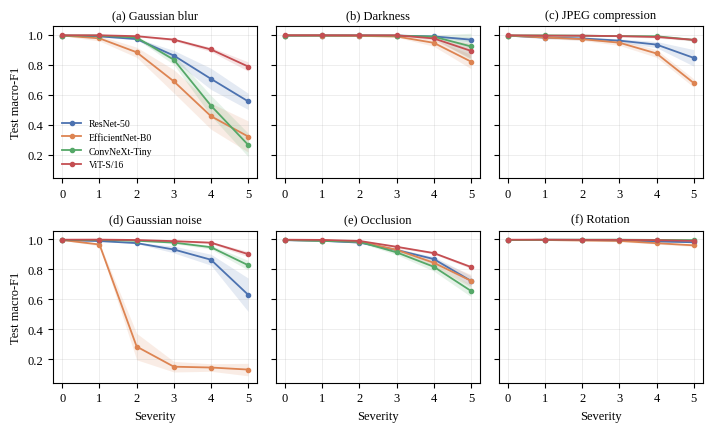

In [2]:
# ---------------- 1. Robustness over five folds
parts = [pd.read_csv(p) for p in find_all("robustness_rows.csv")]
if parts:
    rob = pd.concat(parts).drop_duplicates(["model", "fold", "corruption", "severity", "view"], keep="last")
    print("models:", sorted(rob.model.unique()), "| folds per model:", rob.groupby("model").fold.nunique().to_dict())
    tta = rob[rob.view == "tta"]
    # (a) full table: mean and SD over folds per condition
    full = tta.groupby(["model", "corruption", "severity"]).macro_f1.agg(["mean", "std"]).reset_index()
    full.round(4).to_csv(OUT / "robustness_5fold_all_conditions.csv", index=False)
    # (b) summary per model: clean, each corruption averaged over 5 levels, mean over 30 conditions
    per_fold = (tta.assign(c=np.where(tta.corruption == "clean", "clean", tta.corruption))
                .groupby(["model", "fold", "c"]).macro_f1.mean().unstack("c"))
    per_fold["mean_corrupted"] = tta[tta.corruption != "clean"].groupby(["model", "fold"]).macro_f1.mean()
    per_fold["relative"] = per_fold.mean_corrupted / per_fold.clean
    cols = ["clean", "blur", "dark", "jpeg", "noise", "occlusion", "rotation", "mean_corrupted", "relative"]
    s = per_fold.groupby("model")[cols].agg(["mean", "std"])
    s = s.reindex([m for m in ORDER if m in s.index])
    s.round(4).to_csv(OUT / "robustness_5fold_summary.csv"); display(s.round(3))
    tex = pd.DataFrame({c: [f"{s.loc[m, (c, 'mean')]:.3f} $\\pm$ {s.loc[m, (c, 'std')]:.3f}" for m in s.index] for c in cols},
                       index=[NAME[m] for m in s.index])
    tex.to_csv(OUT / "robustness_5fold_summary_for_latex.csv")
    # (c) does the ranking hold across folds? rank of each model per fold on mean_corrupted
    rk = per_fold.mean_corrupted.unstack("model").rank(axis=1, ascending=False)
    rk.to_csv(OUT / "robustness_rank_per_fold.csv"); print("rank per fold (1 = most robust):"); display(rk)
    # (d) fold 0, single view, against the numbers in the paper
    # Notebook 3 used flip TTA only if recipe F had it (cfg_tta); compare both views and keep the one that matches
    f0 = rob[rob.fold == 0][["model", "view", "corruption", "severity", "macro_f1"]]
    cmp = f0.merge(PAPER_T11, on=["model", "corruption", "severity"], suffixes=("_new", "_paper"))
    cmp["diff"] = cmp.macro_f1_new - cmp.macro_f1_paper
    cmp.round(4).to_csv(OUT / "robustness_fold0_vs_paper.csv", index=False)
    print("fold 0 vs paper, max |difference| per view and corruption (0 = exact reproduction):")
    display(cmp.groupby(["view", "corruption"])["diff"].apply(lambda d: d.abs().max()).unstack("corruption").round(4))
    # (e) figure: macro-F1 against severity, mean +- SD over folds
    plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                         "pdf.fonttype": 42, "font.size": 9})
    LAB = {"blur": "(a) Gaussian blur", "dark": "(b) Darkness", "jpeg": "(c) JPEG compression",
           "noise": "(d) Gaussian noise", "occlusion": "(e) Occlusion", "rotation": "(f) Rotation"}
    COL = {"resnet50": "#4C72B0", "efficientnet_b0": "#DD8452", "convnext_tiny": "#55A868", "vit_small_patch16_224": "#C44E52"}
    fig, axes = plt.subplots(2, 3, figsize=(7.2, 4.4), sharey=True)
    for ax, (c, lab) in zip(axes.ravel(), LAB.items()):
        for m in [m for m in ORDER if m in full.model.unique()]:
            d = pd.concat([full[(full.model == m) & (full.corruption == "clean")],
                           full[(full.model == m) & (full.corruption == c)]]).sort_values("severity")
            ax.plot(d.severity, d["mean"], marker="o", ms=3, lw=1.3, color=COL[m], label=NAME[m])
            ax.fill_between(d.severity, d["mean"] - d["std"].fillna(0), d["mean"] + d["std"].fillna(0), color=COL[m], alpha=0.15, lw=0)
        ax.set_title(lab, fontsize=9); ax.set_xticks(range(6)); ax.grid(alpha=0.3, lw=0.5)
    for ax in axes[1]: ax.set_xlabel("Severity")
    for ax in axes[:, 0]: ax.set_ylabel("Test macro-F1")
    axes[0, 0].legend(fontsize=7, frameon=False, loc="lower left")
    fig.tight_layout()
    for ext in ("pdf", "png"): fig.savefig(OUT / f"res_robustness_5fold.{ext}", dpi=300, bbox_inches="tight")
    plt.show()
    p = find_one("corruption_parameters.csv")
    if p: pd.read_csv(p).to_csv(OUT / "corruption_parameters.csv", index=False)
else:
    print("no robustness output attached")

In [3]:
# ---------------- 2. Grad-CAM, CLIP, CPU timing, checkpoints: copy and tidy
p = find_one("cam_per_image.csv")
if p:
    cam = pd.read_csv(p)
    bf = (cam.groupby(["model", "fold"])
          .agg(on_weapon=("cam_on_weapon", "mean"), on_shifted=("cam_on_shifted", "mean"), on_other=("cam_on_other", "mean"),
               rho_median=("rho", "median"), weapon_area=("weapon_area", "mean")).reset_index())
    if "rollout_on_weapon" in cam:
        bf = bf.merge(cam.groupby(["model", "fold"]).agg(rollout_on_weapon=("rollout_on_weapon", "mean"),
                                                         rollout_on_shifted=("rollout_on_shifted", "mean")).reset_index(), how="left")
    s = bf.drop(columns="fold").groupby("model").agg(["mean", "std"]); s = s.reindex([m for m in ORDER if m in s.index])
    s.round(3).to_csv(OUT / "gradcam_summary_5fold.csv"); display(s.round(3))
    # paired test pooled over folds: attention on weapon vs on shifted mask (image-level, fold 0 only to keep images independent)
    out = []
    for m, g in cam[cam.fold == cam.fold.min()].groupby("model"):
        w = stats.wilcoxon(g.cam_on_weapon, g.cam_on_shifted)
        out.append({"model": m, "n": len(g), "on_weapon": g.cam_on_weapon.mean(), "on_shifted": g.cam_on_shifted.mean(),
                    "images_above_shifted": (g.cam_on_weapon > g.cam_on_shifted).mean(), "wilcoxon_p": w.pvalue})
    pd.DataFrame(out).round(4).to_csv(OUT / "gradcam_vs_shifted_test.csv", index=False); display(pd.DataFrame(out).round(4))
    for f in ["cam_per_class.csv", "cam_per_subset.csv", "gradcam_all_models.pdf", "gradcam_all_models.png"]:
        q = find_one(f)
        if q: (OUT / f).write_bytes(q.read_bytes())
for f in ["clip_zero_shot.csv", "clip_per_class_recall.csv", "clip_confusion_best.csv", "cpu_timing.csv", "pretrained_cfg.csv"]:
    q = find_one(f)
    if q:
        (OUT / f).write_bytes(q.read_bytes()); print("copied", f)
q = find_one("clip_zero_shot.csv")
if q:
    c = pd.read_csv(q); display(c[c.images == "test"].pivot_table(index="model", columns="prompts", values="macro_f1").round(3))

on_weapon        on_shifted        on_other        rho_median        weapon_area      rollout_on_weapon        rollout_on_shifted       
                           mean    std       mean    std     mean    std       mean    std        mean  std              mean    std               mean    std
model                                                                                                                                                         
resnet50                  0.298  0.005      0.016  0.001    0.212  0.001      3.978  0.055       0.088  0.0               NaN    NaN                NaN    NaN
efficientnet_b0           0.226  0.015      0.041  0.006    0.153  0.008      2.805  0.227       0.088  0.0               NaN    NaN                NaN    NaN
convnext_tiny             0.345  0.006      0.014  0.001    0.212  0.005      4.740  0.169       0.088  0.0               NaN    NaN                NaN    NaN
vit_small_patch16_224     0.105  0.041      0.077  0.019    0.095  0.015      1.030  0.435       0.088  0.0             0.173  0.007              0.062  0.007

,model,n,on_weapon,on_shifted,images_above_shifted,wilcoxon_p
0,convnext_tiny,406,0.3474,0.0157,0.9901,0.0000
1,efficientnet_b0,406,0.2515,0.0324,0.9877,0.0000
2,resnet50,406,0.2958,0.0154,0.9951,0.0000
3,vit_small_patch16_224,406,0.1050,0.0781,0.4754,0.1581


copied clip_zero_shot.csv
copied clip_per_class_recall.csv
copied clip_confusion_best.csv
copied pretrained_cfg.csv


prompts,local+description,name,name+templates
model,,,
ViT-B-16 (openai),0.506,0.316,0.317
ViT-B-32 (laion2b_s34b_b79k),0.549,0.448,0.437
ViT-L-14 (laion2b_s32b_b82k),0.666,0.550,0.560
ViT-L-14 (openai),0.707,0.586,0.633


In [4]:
# ---------------- 3. CV statistics with a correction for dependent folds (reviewer item 9)
# Nadeau and Bengio (2003) corrected resampled t-test: var * (1/k + n_test/n_train); for k-fold CV n_test/n_train = 1/(k-1)
RESULTS = {}
for sc in ["all", "single", "multi"]:
    d = next((p for p in INPUT_ROOT.rglob(sc) if p.is_dir() and p.parent.name == "results"
              and (p / "summary_all.csv").exists()), None)
    if d is None: continue
    for fm in d.rglob("fold_metrics.csv"):
        rel = fm.relative_to(d).parts
        if len(rel) == 3:                                   # model / pipeline / fold_metrics.csv
            v = pd.read_csv(fm).sort_values("fold").set_index("fold").macro_f1
            if len(v) == 5: RESULTS[(sc, rel[0], rel[1])] = v
print(len(RESULTS), "runs with five fold scores")

def compare(a, b):
    d = (RESULTS[a] - RESULTS[b]).to_numpy(); k = len(d)
    m, sdv = d.mean(), d.std(ddof=1)
    if sdv == 0:
        return m, sdv, int((d > 0).sum()), 1.0, 1.0
    t_naive = m / (sdv / np.sqrt(k))
    t_corr = m / np.sqrt((1 / k + 1 / (k - 1)) * sdv ** 2)
    p_naive = 2 * stats.t.sf(abs(t_naive), k - 1); p_corr = 2 * stats.t.sf(abs(t_corr), k - 1)
    return m, sdv, int((d > 0).sum()), p_naive, p_corr

def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); n = len(p); adj = np.empty(n)
    adj[o] = np.minimum(1, np.maximum.accumulate((n - np.arange(n)) * p[o]))
    return adj

rows = []
for sc in ["all", "single", "multi"]:
    fam = []
    for ref, pre in (("K1", "K"), ("R1", "R")):                      # (a) ResNet-50 ablation
        for i in range(2, 10):
            a, b = (sc, "resnet50", f"{pre}{i}"), (sc, "resnet50", ref)
            if a in RESULTS and b in RESULTS: fam.append(("ablation", a, b))
    for (s_, m, p) in list(RESULTS):                                  # (b) background kept vs removed
        if s_ == sc and p.startswith("K") and (sc, m, "R" + p[1:]) in RESULTS:
            fam.append(("background", (sc, m, p), (sc, m, "R" + p[1:])))
    fs = {m: RESULTS[(s_, m, p)].mean() for (s_, m, p) in RESULTS if s_ == sc and p == "F"}  # (c) models, recipe F
    if fs:
        best = max(fs, key=fs.get)
        fam += [("models", (sc, m, "F"), (sc, best, "F")) for m in fs if m != best]
    for kind in ("ablation", "background", "models"):
        f = [x for x in fam if x[0] == kind]
        if not f: continue
        r = [compare(a, b) for _, a, b in f]
        hn, hc = holm([x[3] for x in r]), holm([x[4] for x in r])
        for (_, a, b), (m, sdv, nb, pn, pc), h1, h2 in zip(f, r, hn, hc):
            rows.append({"scenario": {"all": "E1", "single": "E2", "multi": "E3"}[sc], "family": kind,
                         "a": f"{a[1]} {a[2]}", "b": f"{b[1]} {b[2]}", "mean_diff": m, "sd_diff": sdv,
                         "folds_a_better": f"{nb}/5", "p_paired_t": pn, "p_holm_paired_t": h1,
                         "p_corrected_t": pc, "p_holm_corrected_t": h2})
st = pd.DataFrame(rows); st.round(4).to_csv(OUT / "cv_statistics_corrected.csv", index=False)
if len(st):
    st["sig_naive"], st["sig_corrected"] = st.p_holm_paired_t < 0.05, st.p_holm_corrected_t < 0.05
    print("significant after Holm (paired t / corrected t):")
    display(st.groupby(["scenario", "family"])[["sig_naive", "sig_corrected"]].sum())
    display(st[st.sig_naive | st.sig_corrected].round(4))

91 runs with five fold scores
significant after Holm (paired t / corrected t):


sig_naive  sig_corrected
scenario family                              
E1       ablation            2              0
         background         12             12
         models              1              0
E2       ablation            3              0
         background         12             12
         models              0              0
E3       ablation            0              0
         background         12              7
         models              1              0

,scenario,family,a,b,mean_diff,sd_diff,folds_a_better,p_paired_t,p_holm_paired_t,p_corrected_t,p_holm_corrected_t,sig_naive,sig_corrected
2,E1,ablation,resnet50 K4,resnet50 K1,-0.0089,0.0023,0/5,0.0009,0.0151,0.0043,0.0691,True,False
12,E1,ablation,resnet50 R6,resnet50 R1,-0.0258,0.0066,0/5,0.0010,0.0151,0.0044,0.0691,True,False
16,E1,background,vit_small_patch16_224 K1,vit_small_patch16_224 R1,0.0384,0.0065,5/5,0.0002,0.0017,0.0009,0.0081,True,True
17,E1,background,resnet50 K1,resnet50 R1,0.0405,0.0052,5/5,0.0001,0.0008,0.0003,0.0038,True,True
18,E1,background,resnet50 K2,resnet50 R2,0.0369,0.0051,5/5,0.0001,0.0009,0.0004,0.0046,True,True
19,E1,background,resnet50 K3,resnet50 R3,0.0357,0.0058,5/5,0.0002,0.0017,0.0008,0.0081,True,True
20,E1,background,resnet50 K4,resnet50 R4,0.0402,0.0124,5/5,0.0019,0.0058,0.0085,0.0253,True,True
21,E1,background,resnet50 K5,resnet50 R5,0.0419,0.0129,5/5,0.0019,0.0058,0.0084,0.0253,True,True
22,E1,background,resnet50 K6,resnet50 R6,0.0569,0.0093,5/5,0.0002,0.0017,0.0008,0.0081,True,True
23,E1,background,resnet50 K7,resnet50 R7,0.0671,0.0154,5/5,0.0006,0.0037,0.0029,0.0172,True,True


In [5]:
# ---------------- 4. Similarity-group sizes (Supplementary Table S15)
mf = next((p for p in INPUT_ROOT.rglob("manifest.csv") if p.parent.name == "metadata" and p.parent.parent.name == "stage0"), None)
if mf is not None:
    man = pd.read_csv(mf, dtype=str)
    print("manifest columns:", list(man.columns))
    gcol = next((c for c in man.columns if "group" in c.lower()), None)
    print("split values:", man.split.value_counts(dropna=False).to_dict() if "split" in man else "-")
    if gcol:
        man = man[man[gcol].notna()]
        sizes = man.groupby(gcol).size()
        bins = [0, 1, 2, 3, 5, 10, 10 ** 9]; labels = ["1", "2", "3", "4-5", "6-10", ">10"]
        def dist(sz):
            c = pd.cut(sz, bins=bins, labels=labels).value_counts().reindex(labels, fill_value=0)
            return {**c.to_dict(), "groups": len(sz), "images": int(sz.sum()), "largest": int(sz.max()),
                    "share_in_groups_of_2plus": round(float(sz[sz > 1].sum() / sz.sum()), 3)}
        rows = [{"class": "All", **dist(sizes)}]
        for lab, g in man.groupby("label"):
            rows.append({"class": lab, **dist(g.groupby(gcol).size())})
        gs = pd.DataFrame(rows); gs.to_csv(OUT / "group_sizes.csv", index=False); display(gs)
        for col in [c for c in man.columns if c.lower() in ("split", "fold", "cv_fold")]:
            n = (man.groupby(gcol)[col].nunique() > 1).sum()
            print(f"groups that cross '{col}': {n}")
        mixed = (man.groupby(gcol).label.nunique() > 1).sum()
        print("groups with more than one class:", mixed)
    else:
        print("no group column in the manifest; look for the grouping file of Stage 0 (e.g. groups.csv)")
        g2 = next((p for p in INPUT_ROOT.rglob("*group*.csv")), None); print("candidate:", g2)

with zipfile.ZipFile(WORK / "v2_merged_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in OUT.iterdir():
        z.write(f, f"v2_merged/{f.name}")
print("Done: send", WORK / "v2_merged_results.zip")

manifest columns: ['image_id', 'path', 'label', 'label_idx', 'subset', 'part', 'orig_label', 'split', 'fold', 'group_id', 'rel_path', 'width', 'height', 'orig_w', 'orig_h', 'upscale_candidate', 'lap_var', 'mean_lum', 'std_lum', 'mean_sat', 'qc_flags']
split values: {'trainval': 2531, 'test': 419}


,class,1,2,3,4-5,6-10,>10,groups,images,largest,share_in_groups_of_2plus
0,All,2281,137,35,33,9,6,2501,2950,21,0.227
1,Churi,393,41,8,5,0,0,447,521,5,0.246
2,Dao,448,30,2,4,0,0,484,530,4,0.155
3,Khor,231,25,11,12,4,5,288,471,21,0.510
4,Kodal,452,9,1,1,0,0,463,477,4,0.052
5,Kural,383,18,3,6,2,1,413,477,12,0.197
6,Shabol,380,11,10,5,3,0,409,474,9,0.198


groups that cross 'split': 0
groups that cross 'fold': 0
groups with more than one class: 3
Done: send /kaggle/working/v2_merged_results.zip
